# Construir y validar un plan minero condicionado por el estado

**Pregunta:** ¿Cómo elige una política entre los bloques que siguen siendo factibles en cada decisión?

**Nivel 2.** Método en práctica.

**Prerequisitos:** Lee las lecciones correspondientes sobre estado de frontera y diseño de particiones. **Tiempo estimado:** 45 minutos.

## Objetivos

Esta lección guiada sigue un grafo sintético pequeño a través del contrato de planificación condicionado por el estado. Generarás una instancia repetible, inspeccionarás variables de nodo con nombre, ajustarás un normalizador solo con datos de entrenamiento, distinguirás la disponibilidad por precedencia de la factibilidad completa de recursos, avanzarás una política transparente y validarás las asignaciones exportadas desde la instancia original. El ejercicio se concentra en decisiones que pueden auditarse estado por estado. No entrena una red neuronal, no estima el desempeño en yacimientos desconocidos ni representa una mina en operación. Trata los valores generados como datos sintéticos para desarrollar el método y conserva las unidades declaradas en cada comparación.

## Preparación

Ejecuta desde la raíz del repositorio con las dependencias fijadas del notebook. La lección importa el generador de grafos y las primitivas de planificación del producto; no vuelve a definir esas funciones. No requiere acceso a la red, pesos del modelo, datos privados ni trabajos de entrenamiento. Una semilla y versión de generador fijas hacen reproducible la entrada. Las versiones de paquetes importan porque cambios del generador, solucionador o biblioteca numérica pueden alterar los planes. Si el entorno no coincide con las versiones, detente y prepara el entorno declarado en vez de sustituir otra implementación.

Comando para preparar el entorno:

```bash
python -m pip install oreblocks==0.6.6 numpy==2.5.1 matplotlib==3.11.2
```

In [1]:
# Importa paquetes fijados y primitivas públicas de la frontera del producto.
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.frontier_data import generate_graph, FEATURE_NAMES
from pipeline.model.frontier_policy import (
    FeatureNormalizer,
    feasible_frontier,
    precedence_frontier,
    replay_frontier_policy,
    validate_schedule,
)
from pipeline.model.frontier_policy import FrontierInstance
import importlib.metadata

print({name: importlib.metadata.version(name) for name in ("oreblocks", "numpy", "matplotlib")})


{'oreblocks': '0.6.6', 'numpy': '2.5.1', 'matplotlib': '3.11.2'}


## Datos

Cada bloque generado tiene una fila canónica, valor económico finito, consumo no negativo de recursos mineros y de procesamiento, un conjunto acíclico de predecesores inmediatos y una fila de capacidad por período. Las aristas apuntan desde el requisito hacia el bloque dependiente. El generador también entrega una matriz de variables con nombres cuyo orden forma parte del contrato. El ejemplo usa geometría de cruces y un tamaño fijo. Es sintético: ni las leyes ni los valores provienen de MineLib o de operaciones licenciadas. No se usa ni redistribuye un conjunto de datos externo; la licencia MIT del repositorio se aplica al código, no a datos de terceros. Fuente: https://github.com/fsantibanezleal/CAOS_PhaseFlow. Mantén identificadores, etiquetas, resultados y pertenencia a particiones fuera de la matriz de variables.

Genera filas de ajuste separadas del grafo que vas a inspeccionar.

In [2]:
# Genera grafos separados de entrenamiento y un grafo de decisión inspeccionable.
train_graphs = [generate_graph(seed, "benched", 64, periods=8) for seed in range(10_101, 10_111)]
case = generate_graph(20_007, "crosscut", 96, periods=8)
train_matrix = np.vstack([g.node_features for g in train_graphs])
normalizer = FeatureNormalizer.fit(train_matrix, FEATURE_NAMES, declared_features=FEATURE_NAMES)
case_features = normalizer.transform(case.node_features, FEATURE_NAMES)
print(
    {
        "generator": case.family_parameters,
        "features": FEATURE_NAMES,
        "shape": case_features.shape,
        "normalizer_sha256": normalizer.sha256,
    }
)
print({"check": bool(np.isfinite(case_features).all())})


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'features': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'), 'shape': (96, 7), 'normalizer_sha256': '6e903528660b420aaad208f787c997402decb7381e82fbf50b0d1171f7778e8e'}
{'check': True}


Construye un segundo grafo de otra familia para que el normalizador no se ajuste con sus filas de evaluación.

In [3]:
# Genera el grafo separado que se inspeccionará y programará.
case = generate_graph(20_007, "crosscut", 96, periods=8)
print(
    {"generator": case.family_parameters, "blocks": len(case.instance.values), "feature_names": FEATURE_NAMES}
)


{'generator': 'frontier-graphs/1.0.0:crosscut:size=96:periods=8:v1', 'blocks': 96, 'feature_names': ('value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count')}


## Método

En el período t, la frontera de precedencia contiene bloques sin asignar cuyos requisitos ya fueron programados hasta t. El filtro de recursos resta el uso del período a cada capacidad y conserva un bloque solo si cabe su vector completo de recursos. Por eso una acción puede estar lista según el grafo y aun así quedar excluida por capacidad minera o de procesamiento. Las acciones explícitas de detener el período y detener el plan hacen representables una frontera vacía y una terminación deliberada. En un actor aprendido, los mensajes del grafo resumen estructura local, el estado dinámico describe el período y los recursos restantes, y una máscara excluye logits de bloques inadmisibles antes de elegir. La puntuación transparente de esta lección solo prueba esa interfaz; no es el actor entrenado.

La revisión también debe comparar el prefijo de asignaciones con el vector de capacidad restante tras cada cambio de período. Así se observa si una alternativa desapareció por un requisito aún pendiente o por un recurso específico que limita. La distinción es esencial cuando el modelo elige repetidamente detener el período o devuelve un plan breve. Un conjunto factible solo garantiza que las acciones expuestas caben en el estado declarado; no garantiza que la política elija una acción valiosa. Registra la dimensión limitante y el período actual en la salida de depuración. Esa traza explica una frontera vacía y ayuda a distinguir un presupuesto de recursos estrecho de un error al indexar predecesores. Estos diagnósticos mejoran la claridad de ingeniería sin agregar una afirmación sobre calidad económica.

$$E_t=\{b\in\mathcal{B}\setminus A: P_b\subseteq A\}.$$

$$F_t=\{b\in E_t: r_b\leq C_t-u_t\ \text{componente a componente}\}.$$

Aquí $\mathcal{B}$ es el conjunto de bloques, $A$ los bloques asignados, $P_b$ los predecesores inmediatos de $b$, $C_t$ la capacidad del período $t$, $u_t$ su uso y $r_b$ el vector de recursos del bloque. La definición usa las restricciones de precedencia y capacidad de la programación a cielo abierto; consulta las fuentes citadas.

Mide los dos conjuntos candidatos antes de elegir una acción.

In [4]:
# Compara la elegibilidad estructural con la factibilidad del vector completo de recursos.
instance = case.instance
ready = precedence_frontier(instance, (), 0)
feasible = feasible_frontier(instance, (), 0)
print(
    {
        "period_zero_ready": len(ready),
        "period_zero_feasible": len(feasible),
        "capacity_removed": len(ready) - len(feasible),
    }
)
print({"check": bool(set(feasible).issubset(ready))})


{'period_zero_ready': 1, 'period_zero_feasible': 1, 'capacity_removed': 0}
{'check': True}


Reproduce una puntuación transparente y recalcula el valor del plan de forma independiente.

In [5]:
# Reproduce una puntuación transparente, valida el plan e inspecciona la decisión terminal.
score = lambda b, p, a: float(instance.values[b]) if b >= 0 else -1.0
result = replay_frontier_policy(instance, score, tonnage=case.tonnage)
independent_value = validate_schedule(instance, result.assignments)
print({"check": bool(np.isclose(independent_value, result.npv))})
terminal_period = len(instance.capacities) - 1
terminal_frontier = feasible_frontier(instance, result.assignments, terminal_period)
terminal_scores = {block: score(block, terminal_period, result.assignments) for block in terminal_frontier}
print(
    {
        "assignments": len(result.assignments),
        "independent_npv": independent_value,
        "stop_reason": result.stopped,
        "terminal_period": terminal_period,
        "terminal_feasible_scores": terminal_scores,
        "stop_period_score": -1.0,
        "tonnage_coverage": result.tonnage_coverage,
        "positive_value_coverage": result.positive_value_coverage,
    }
)


{'check': True}
{'assignments': 21, 'independent_npv': 6.5810534023261145, 'stop_reason': 'horizon-complete', 'terminal_period': 7, 'terminal_feasible_scores': {16: -1.5234345006037069}, 'stop_period_score': -1.0, 'tonnage_coverage': 0.2030469209123082, 'positive_value_coverage': 0.19394082509847316}


Reconstruye cada decisión desde las asignaciones previas para verificar su elegibilidad.

In [6]:
# Reconstruye los conteos de cada decisión usando el prefijo previo de asignaciones.
prefix = []
ready_counts = []
feasible_counts = []
for assignment in result.assignments:
    ready_counts.append(len(precedence_frontier(instance, prefix, assignment.period)))
    feasible_counts.append(len(feasible_frontier(instance, prefix, assignment.period)))
    print({"check": bool(assignment.block in feasible_frontier(instance, prefix, assignment.period))})
    prefix.append(assignment)
print({"check": bool(len(prefix) == len(result.assignments))})


{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}
{'check': True}


### Comparación

La primera figura compara la cantidad de alternativas listas por precedencia con el conjunto factible más pequeño durante la reproducción. Una diferencia se debe al filtro de recursos porque ambas llamadas reciben el mismo prefijo de asignaciones. La segunda figura compara dos consumos con sus capacidades por período. No se deben colapsar las unidades en una sola suma: disponer de capacidad minera no implica disponer de suficiente procesamiento. El normalizador se ajusta solo con variables de entrenamiento y se conserva fijo para inferencia; esta figura no compara el rendimiento entre escalas. Los conteos graficados no ordenan el desempeño.

### Evidencia

La evidencia es local y mecánica. La salida registra semilla, contrato del generador, nombres de variables, hash del normalizador, conteos de acciones, asignaciones, objetivo recalculado independientemente, cargas de recursos y cobertura. Los diagnósticos impresos muestran si las variables transformadas son finitas y si coinciden el replay y el cálculo independiente del objetivo. La función de reproducción rechaza asignaciones infactibles antes de devolver un resultado. Las figuras se generan desde esos objetos presentes en memoria. Este ejemplo reproducible de software no demuestra factibilidad para otra entrada, calidad del entrenamiento, valor económico ni transferencia fuera de este grafo.

La figura cuenta los bloques listos por precedencia y los factibles por recursos antes de cada acción seleccionada. Interpreta la diferencia entre las líneas como exclusiones del chequeo del vector completo de recursos.

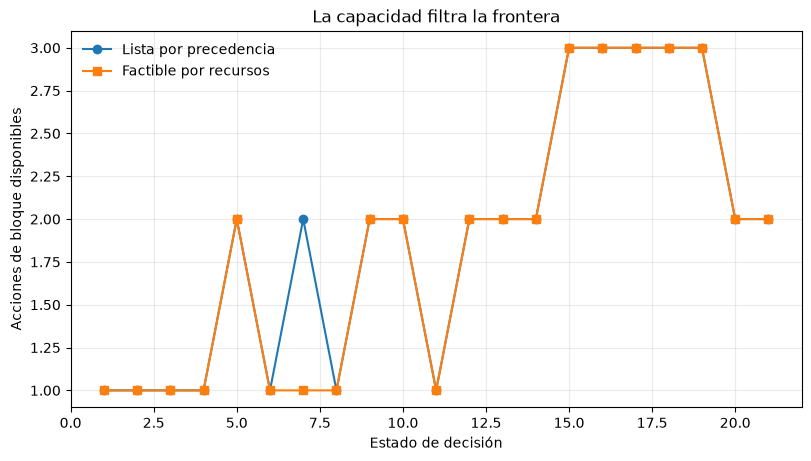

In [7]:
# Grafica cómo se reduce el conjunto de acciones factibles durante la reproducción.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
steps = np.arange(1, len(ready_counts) + 1)
ax.plot(steps, ready_counts, marker="o", label="Lista por precedencia")
ax.plot(steps, feasible_counts, marker="s", label="Factible por recursos")
ax.set(
    xlabel="Estado de decisión",
    ylabel="Acciones de bloque disponibles",
    title="La capacidad filtra la frontera",
)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
plt.show()


Las líneas coinciden en casi todos los estados; solo se contraen en el estado 7, donde dos bloques cumplen precedencia pero solo uno cabe en el vector residual de recursos. Es un efecto de la máscara, no una comparación de puntuaciones. La gráfica no muestra si la capacidad bloquea una cadena valiosa en estados posteriores. Inspecciona el uso de recursos y la traza de acciones antes de identificar el recurso limitante o un efecto económico.

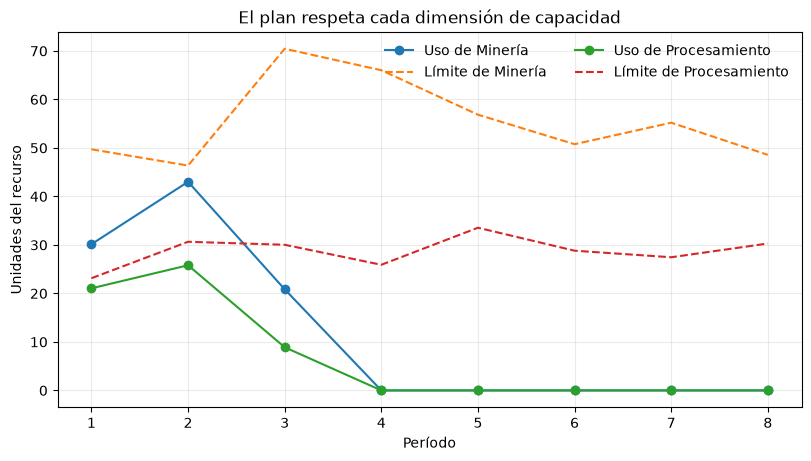

In [8]:
# Compara cada carga de recursos con su propia capacidad por período.
usage = np.zeros_like(instance.capacities)
for assignment in result.assignments:
    usage[assignment.period] += instance.resources[assignment.block]
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
periods = np.arange(1, len(instance.capacities) + 1)
for resource, name in enumerate(("Minería", "Procesamiento")):
    ax.plot(periods, usage[:, resource], marker="o", label=f"Uso de {name}")
    ax.plot(periods, instance.capacities[:, resource], linestyle="--", label=f"Límite de {name}")
ax.set(xlabel="Período", ylabel="Unidades del recurso", title="El plan respeta cada dimensión de capacidad")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2)
plt.show()


Esta gráfica deriva las cargas de las asignaciones y compara cada recurso con su propia capacidad por período. Los períodos 4–8 tienen carga cero pese a contar con capacidad positiva. El plan deja de asignar bloques antes de agotar el horizonte; para explicar por qué hay que inspeccionar los bloques factibles restantes y las puntuaciones de las acciones de detención.

Compara ahora los resultados impresos para los cuatro multiplicadores de capacidad. Mantén fijos el grafo, los valores, las variables y la puntuación transparente para que solo cambie la matriz de capacidad.

{'factors': [0.7, 0.85, 1.0, 1.15], 'coverage_npv': [(0.19394082509847316, 6.260983374702888), (0.19394082509847316, 6.402517817175093), (0.19394082509847316, 6.5810534023261145), (0.19394082509847316, 6.5393945154820035)]}


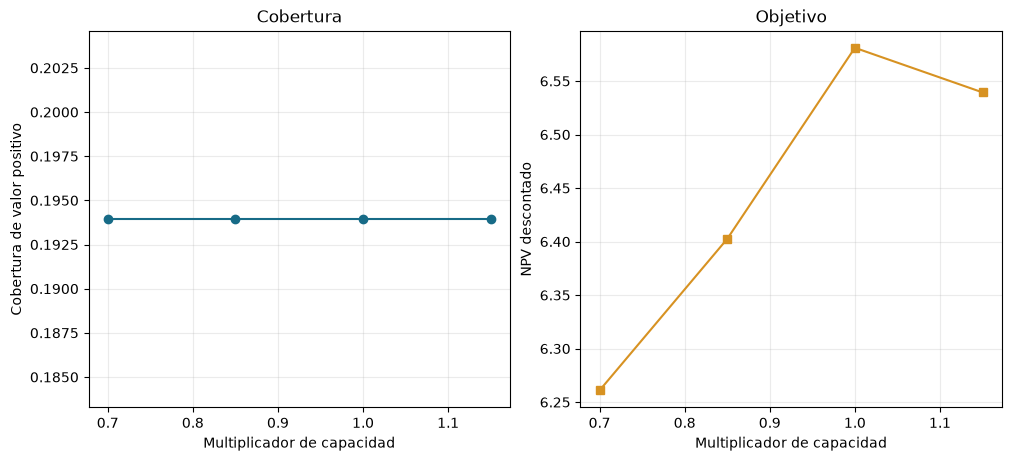

In [9]:
# Reproduce la misma puntuación con varios límites uniformes de capacidad.
from dataclasses import replace

factors = np.array([0.70, 0.85, 1.00, 1.15])
sweep = []
for factor in factors:
    variant = replace(instance, capacities=instance.capacities * factor)
    replay = replay_frontier_policy(variant, score, tonnage=case.tonnage)
    sweep.append((replay.positive_value_coverage, replay.npv))
print({"factors": factors.tolist(), "coverage_npv": sweep})
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
axes[0].plot(factors, [row[0] for row in sweep], marker="o", color="#176B87")
axes[0].set(xlabel="Multiplicador de capacidad", ylabel="Cobertura de valor positivo", title="Cobertura")
axes[1].plot(factors, [row[1] for row in sweep], marker="s", color="#D79222")
axes[1].set(xlabel="Multiplicador de capacidad", ylabel="NPV descontado", title="Objetivo")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


Para esta semilla, la cobertura de valor positivo permanece constante en los cuatro multiplicadores; el NPV descontado sube hasta el multiplicador 1.0 y cae en 1.15. Esa respuesta no monótona refleja cambios de período en las asignaciones bajo esta puntuación. Es sensibilidad de un caso, no robustez entre yacimientos ni comparación de políticas.

## Resultados

Interpreta el tamaño de la máscara como la cantidad de acciones que la política puede elegir legalmente en ese estado, no como una puntuación. Interpreta el objetivo junto con la cobertura: un plan parcial factible puede dejar bloques de valor positivo y toneladas sin asignar. El validador recalcula unicidad, precedencia, cada dimensión de capacidad y valor descontado desde la instancia original, así que una máscara válida anterior no excusa una exportación alterada. Este es el recorrido completo de la mecánica del método. Las afirmaciones empíricas corresponden a una evaluación congelada por separado; la lección de evidencia explica por qué el diagnóstico actual no puede cumplir ese papel.

**Respuesta:** La reproducción asigna 21 bloques y el validador independiente devuelve NPV 6.5811. En el período 7, el bloque 16 sigue siendo factible, pero su puntuación es -1.5234, menor que -1 para detener el período. La función termina con un plan válido pero parcial: la máscara garantiza elecciones legales, no una jerarquía útil ni la finalización.

## Resumen

El límite del método es claro: la estructura del grafo y el estado parcial informan las puntuaciones, la máscara de factibilidad restringe las elecciones y un validador independiente comprueba el resultado exportado. El normalizador de entrenamiento tiene un hash para que la inferencia use exactamente el mismo orden y escala de variables. Al adaptar la canalización, conserva identificadores canónicos, unidades de origen, procedencia de particiones, razones de detención y ambas medidas de cobertura. No atribuyas una frontera vacía al modelo antes de revisar precedencias y cada recurso residual. Esta lección da un ejemplo auditable de mecánica, no una comparación ni recomendación de despliegue.

### Sensibilidad y límites

El barrido anterior varía toda la matriz de capacidades mediante un multiplicador declarado. Es una comprobación local de sensibilidad, no un estudio de robustez. Para identificar qué recurso afecta una decisión, varía por separado las columnas de minería y procesamiento, manteniendo las demás fijas; luego repite con una pequeña grilla factorial para detectar interacciones. Conserva la instancia original y crea una variante inmutable por ejecución. Registra el multiplicador, las columnas modificadas, la razón de detención, el objetivo, ambas coberturas y el resultado del validador en una tabla por caso. Grafica cada salida frente al parámetro y conserva los casos sin acciones. Si una métrica cambia abruptamente, inspecciona la traza alrededor del umbral: la precedencia puede hacer que un cambio pequeño de recursos libere una cadena de bloques.

Repite el ejercicio con varias familias y tamaños de grafo antes de describir un patrón. Usa el mismo conjunto de semillas para comparaciones pareadas y separa las semillas usadas para ajustar una política de las usadas para resumir su comportamiento. Informa la distribución completa y la cantidad de casos intentados, incluidas generaciones fallidas y rechazos del validador. Un solo grafo no estima incertidumbre ni demuestra estabilidad. El grafo de esta lección es sintético y la puntuación determinista es una sonda didáctica. Ni el barrido ni el validador miden realismo geológico, costos operacionales, confianza de reservas o aceptabilidad del plan. Esas preguntas requieren datos del dominio, un modelo económico aprobado y revisión independiente.

Para una tabla diagnóstica útil, conserva una fila por cada combinación de grafo, variante de recursos y configuración de política. Guarda el vector de capacidades original junto al multiplicador para que otro analista pueda reconstruir el experimento. Compara trazas para identificar la primera decisión divergente; las diferencias agregadas de objetivo pueden ocultar un cambio de período o un requisito limitante. Prueba el validador con planes alterados deliberadamente, incluidos bloques duplicados, precedencia invertida y asignaciones sobre capacidad, y confirma que informe cada infracción. Son verificaciones de software, no evidencia de generalización. Mantén los casos de desarrollo separados de cualquier evaluación congelada posterior y registra los cambios de protocolo antes de inspeccionar sus resultados.

También revisa si los empates se resuelven de forma determinista, si las acciones de detención pueden elegirse cuando aún hay bloques factibles y si los períodos de descuento respetan el índice declarado. Un desajuste pequeño del contrato puede cambiar el plan aunque cada asignación parezca admisible. Guarda la configuración completa con cada traza para distinguir cambios de capacidad, puntuación o versión de implementación.

### Uso con datos propios

Comienza con un contrato de entrada versionado. Mantén un identificador estable por bloque; declara unidades de valor, tonelaje, capacidad minera, capacidad de procesamiento y período de descuento; y conserva la procedencia de cada campo fuente. Valida valores finitos, consumos no negativos, identificadores únicos, aristas acíclicas y filas completas de capacidad antes de construir el grafo. Resuelve duplicados y datos faltantes mediante reglas documentadas, no imputaciones silenciosas. Evita variables derivadas de resultados y etiquetas económicas como entradas, y conserva el vínculo con registros fuente en un entorno controlado.

Construye particiones por yacimiento u otra agrupación geológica independiente cuando corresponda al uso esperado. Congela el manifiesto antes de seleccionar el modelo, ajusta el escalado solo con entrenamiento y reutiliza orden y hash de variables durante la inferencia. Ejecuta una línea base transparente sobre los mismos casos y conserva resultados pareados. Por política, persiste hash de entrada, configuración, semilla, checkpoint elegido, traza de acciones, razón de detención, hallazgos del validador, objetivo y ambas coberturas. Escribe cada caso de forma atómica para reanudar una evaluación interrumpida sin repetir los casos terminados. Solicita revisión independiente del validador y de las conversiones de unidades antes de usar resultados en una decisión real de planificación.

Durante la depuración, inspecciona el primer punto donde divergen dos trazas de acciones comparables. Reconstruye el conjunto elegible, la capacidad restante, el estado de predecesores, el vector de puntuaciones y la regla de desempate en ese paso. Así puedes separar el efecto de una variable o puntuación de un error de índice, conversión de capacidad u orden no determinista. Mantén un grafo pequeño y calculable a mano con un óptimo conocido junto a los casos mayores, pero identifícalo como fixture del contrato, no como evidencia representativa de una mina. Ante un cambio de código, reproduce la misma entrada y configuración inmutables y compara primero los estados por paso y luego los objetivos finales. Registra la versión del paquete y el commit fuente con cada traza para reproducir el diagnóstico.

Mapea tu tabla de bloques a índices canónicos: `values` tiene forma `(n_blocks,)`, `resources` `(n_blocks, n_resources)`, `predecessors` usa esas mismas posiciones de fila y `capacities` tiene forma `(n_periods, n_resources)`. Declara las unidades y la convención de descuento. `FrontierInstance` deja sin descuento el período cero por defecto (`period_one_undiscounted=True`). Los cuatro registros siguientes son una prueba sintética del contrato; reemplázalos por una tabla fuente validada y con acceso controlado antes de analizar datos reales.

In [10]:
# Construye un caso explícito; los valores y las unidades de recursos son ilustrativos.
own_data_instance = FrontierInstance(
    values=np.array([40.0, 25.0, 22.0, 18.0]),
    resources=np.array([[2.0, 1.0], [1.0, 1.0], [2.0, 1.0], [1.0, 2.0]]),
    predecessors=((), (0,), (0,), (1, 2)),
    capacities=np.array([[2.0, 2.0], [3.0, 2.0], [3.0, 3.0]]),
    discount_rate=0.08,
)
own_tonnage = np.array([100.0, 60.0, 70.0, 40.0])
own_score = lambda block, period, assigned: own_data_instance.values[block] if block >= 0 else -1.0
own_result = replay_frontier_policy(own_data_instance, own_score, tonnage=own_tonnage)
print(
    {
        "assigned_blocks": len(own_result.assignments),
        "npv": own_result.npv,
        "tonnage_coverage": own_result.tonnage_coverage,
        "positive_value_coverage": own_result.positive_value_coverage,
        "stop": own_result.stopped,
    }
)


{'assigned_blocks': 4, 'npv': 98.95061728395062, 'tonnage_coverage': 1.0, 'positive_value_coverage': 1.0, 'stop': 'horizon-complete'}


## Referencias

El objetivo de gradiente de política recortado da contexto al algoritmo de entrenamiento; el repositorio de PhaseFlow documenta su contrato de acciones, preprocesamiento y validador. Estas fuentes no trasladan afirmaciones de desempeño al ejemplo sintético. Cada valor numérico se calcula al ejecutar el notebook.

- Método de gradiente de política: https://arxiv.org/abs/1707.06347
- Optimizador adaptativo: https://arxiv.org/abs/1412.6980
- Formulación de planificación a cielo abierto: https://doi.org/10.1287/inte.2013.0731
- Implementación y registros: https://github.com/fsantibanezleal/CAOS_PhaseFlow